# 🏪 Retail Sales Insights — Exploratory Analysis

**Question:** What drives revenue across our three stores, which customers matter most, and what should we expect over the next six months?

**Data:** ~264k point-of-sale line items (Nov 2024 – Oct 2026), generated by `data/generate_data.py` to mirror a real POS export — including the messy parts (duplicates, returns, missing values, inconsistent labels).

**Contents**
1. Load & audit data quality
2. Clean
3. Revenue trends & seasonality
4. Products & categories
5. Customer segmentation (RFM + K-Means)
6. Forecast
7. Recommendations

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from src.analysis import PALETTE, load_raw, clean, kpis, monthly, rfm_segments, forecast_monthly, restock_suggestions

sns.set_theme(style='whitegrid', palette=PALETTE, rc={'axes.facecolor': '#faf6ef', 'figure.facecolor': '#faf6ef', 'grid.color': '#e7dccb', 'axes.edgecolor': '#e7dccb'})
plt.rcParams.update({'figure.figsize': (11, 4.2), 'axes.titleweight': 'bold', 'axes.titlesize': 13})
millions = mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M')

## 1. Load & audit data quality

In [2]:
raw = load_raw()
print(f'{len(raw):,} rows × {raw.shape[1]} columns')
raw.head()

264,064 rows × 11 columns


,receipt_no,timestamp,store,customer_id,product,category,quantity,unit_price,unit_cost,discount_pct,payment_method
0,BX-100033,2024-11-01 08:04:00,Clifton,C11427,Mineral Water 1.5L,Beverages,2,120,80,0.10,cash
1,BX-100033,2024-11-01 08:10:00,Clifton,C11427,Potato Chips 150g,Snacks,2,280,190,0.00,cash
2,BX-100033,2024-11-01 08:36:00,Clifton,C11427,USB-C Cable 1m,Electronics,1,900,520,0.05,cash
3,BX-100033,2024-11-01 08:45:00,Clifton,C11427,Soft Drink 1.5L,Beverages,2,220,150,0.00,cash
4,BX-100041,2024-11-01 09:06:00,Clifton,C11645,Mineral Water 1.5L,Beverages,2,120,80,0.00,wallet


In [3]:
audit = pd.DataFrame({
    'missing values': raw.isna().sum(),
    'unique values': raw.nunique(),
})
print('Exact duplicate rows:', raw.duplicated().sum())
print('Negative quantities (returns):', (raw['quantity'] < 0).sum())
print('Store labels:', sorted(raw['store'].unique()))
audit

Exact duplicate rows: 1010
Negative quantities (returns): 1569
Store labels: ['CLIFTON', 'Clifton', 'DHA', 'GULSHAN', 'Gulshan']


,missing values,unique values
receipt_no,0,106210
timestamp,0,203341
store,0,5
customer_id,66217,1799
product,0,18
category,0,6
quantity,0,8
unit_price,0,17
unit_cost,0,18
discount_pct,0,3


**Findings:** duplicate rows from a double export, ~0.6% returns recorded as negative quantities, upper-case store names, missing payment methods, and `customer_id` blank for walk-in customers (expected — not an error).

## 2. Clean

In [4]:
df = clean(raw)
print(f'{len(raw) - len(df):,} duplicate rows removed → {len(df):,} rows')
print('Stores after fix:', sorted(df['store'].unique()))
k = kpis(df)
pd.Series({
    'Revenue (PKR)': f"{k['revenue']:,.0f}",
    'Gross profit (PKR)': f"{k['profit']:,.0f}",
    'Margin': f"{k['margin']:.1%}",
    'Transactions': f"{k['transactions']:,}",
    'Average basket (PKR)': f"{k['avg_basket']:,.0f}",
    'Return rate': f"{k['return_rate']:.2%}",
}).to_frame('value')

1,022 duplicate rows removed → 263,042 rows
Stores after fix: ['Clifton', 'DHA', 'Gulshan']


,value
Revenue (PKR),"316,203,830"
Gross profit (PKR),"65,693,230"
Margin,20.8%
Transactions,"104,652"
Average basket (PKR),"3,039"
Return rate,0.60%


## 3. Revenue trends & seasonality

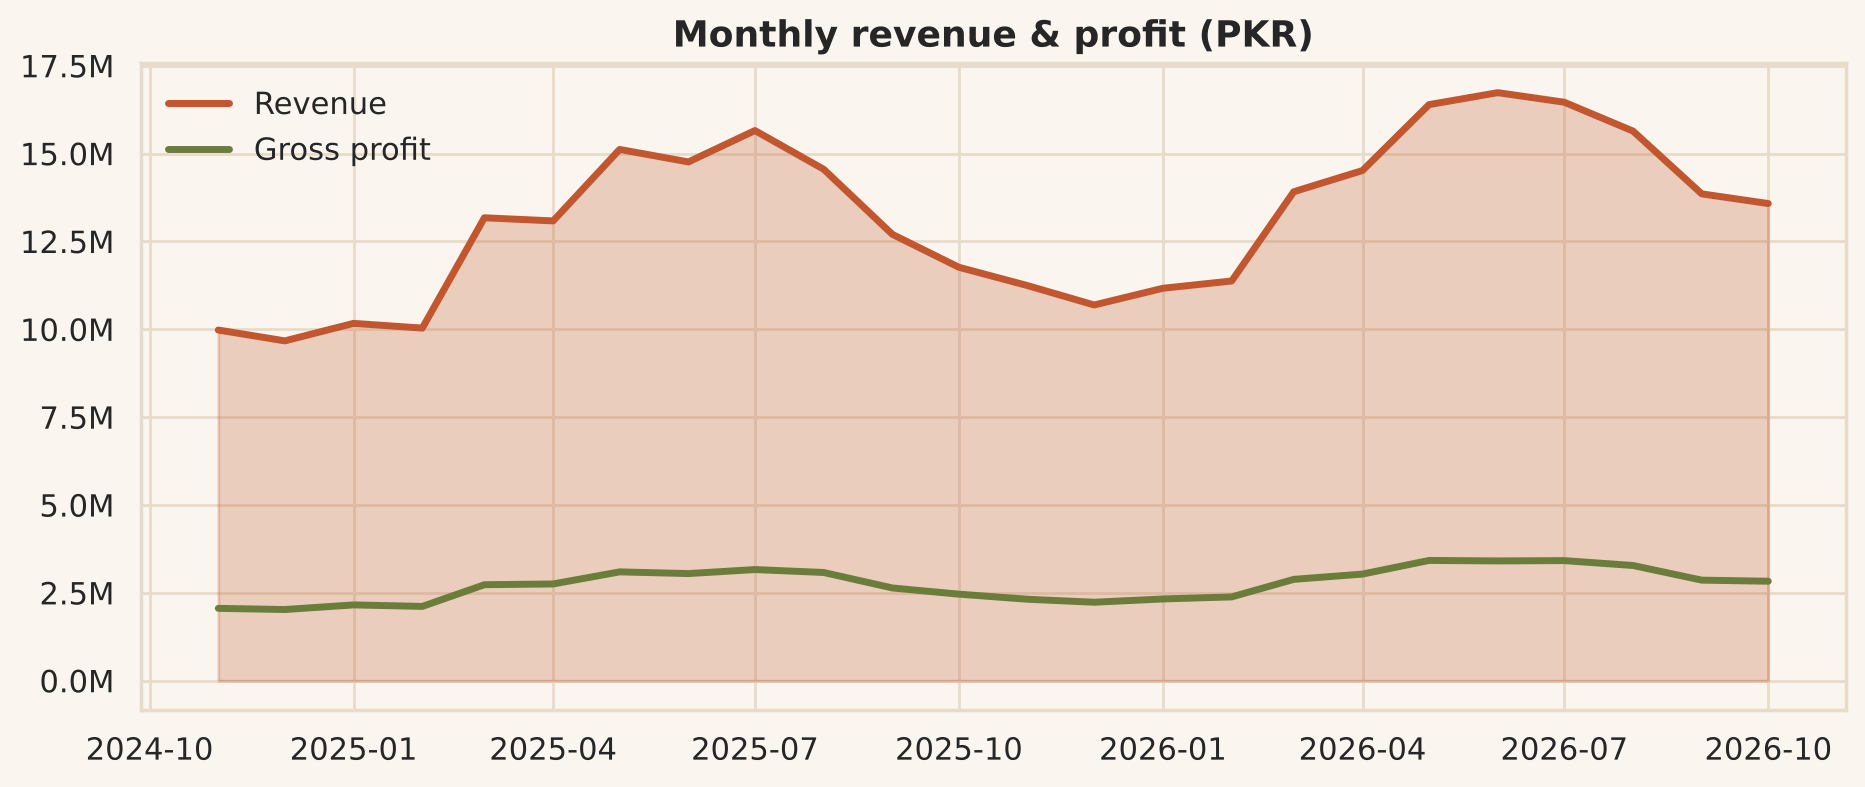

Last-3-month average revenue is +44.5% vs the first 3 months.


In [5]:
m = monthly(df)
fig, ax = plt.subplots()
ax.fill_between(m['month'], m['revenue'], color=PALETTE[0], alpha=.25)
ax.plot(m['month'], m['revenue'], color=PALETTE[0], lw=2.5, label='Revenue')
ax.plot(m['month'], m['profit'], color=PALETTE[1], lw=2.5, label='Gross profit')
ax.yaxis.set_major_formatter(millions); ax.set_title('Monthly revenue & profit (PKR)'); ax.legend(frameon=False)
plt.show()
growth = m['revenue'].tail(3).mean() / m['revenue'].head(3).mean() - 1
print(f'Last-3-month average revenue is {growth:+.1%} vs the first 3 months.')

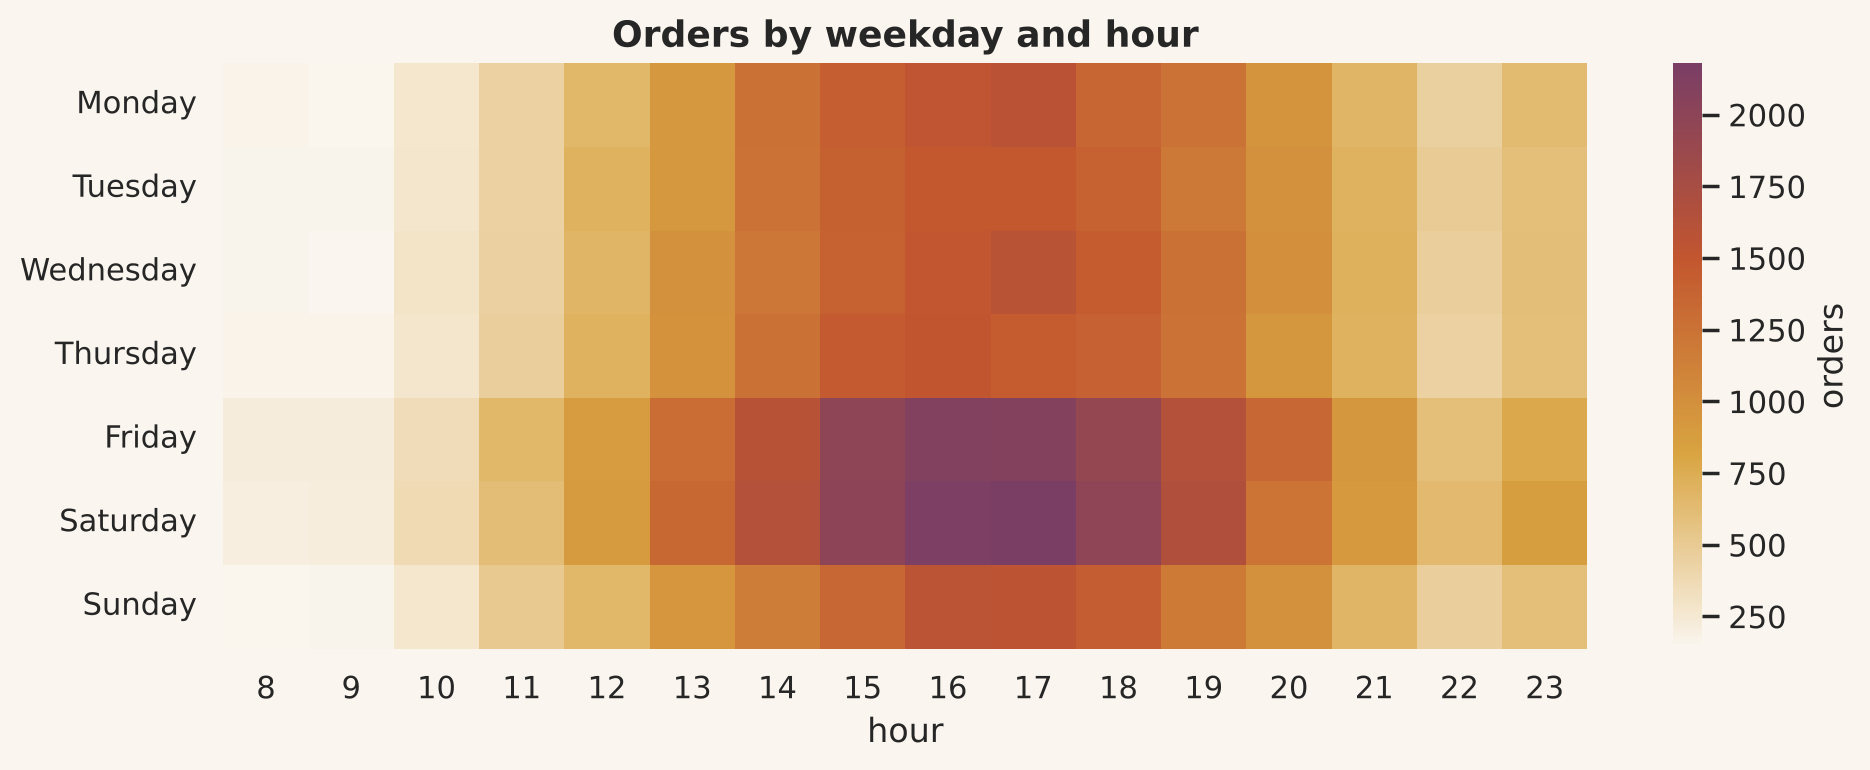

In [6]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heat = df.pivot_table(index='weekday', columns='hour', values='receipt_no', aggfunc='nunique').reindex(order)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(heat, cmap=sns.blend_palette(['#faf6ef', '#d9a441', '#c2562f', '#7a3e65'], as_cmap=True), ax=ax, cbar_kws={'label': 'orders'})
ax.set_title('Orders by weekday and hour'); ax.set_xlabel('hour'); ax.set_ylabel('')
plt.show()

**Insight:** Friday and Saturday evenings (5–8 pm) are the peak — that's where cashier coverage and shelf replenishment matter most. A demand spike is also visible around the Ramadan months.

## 4. Products & categories

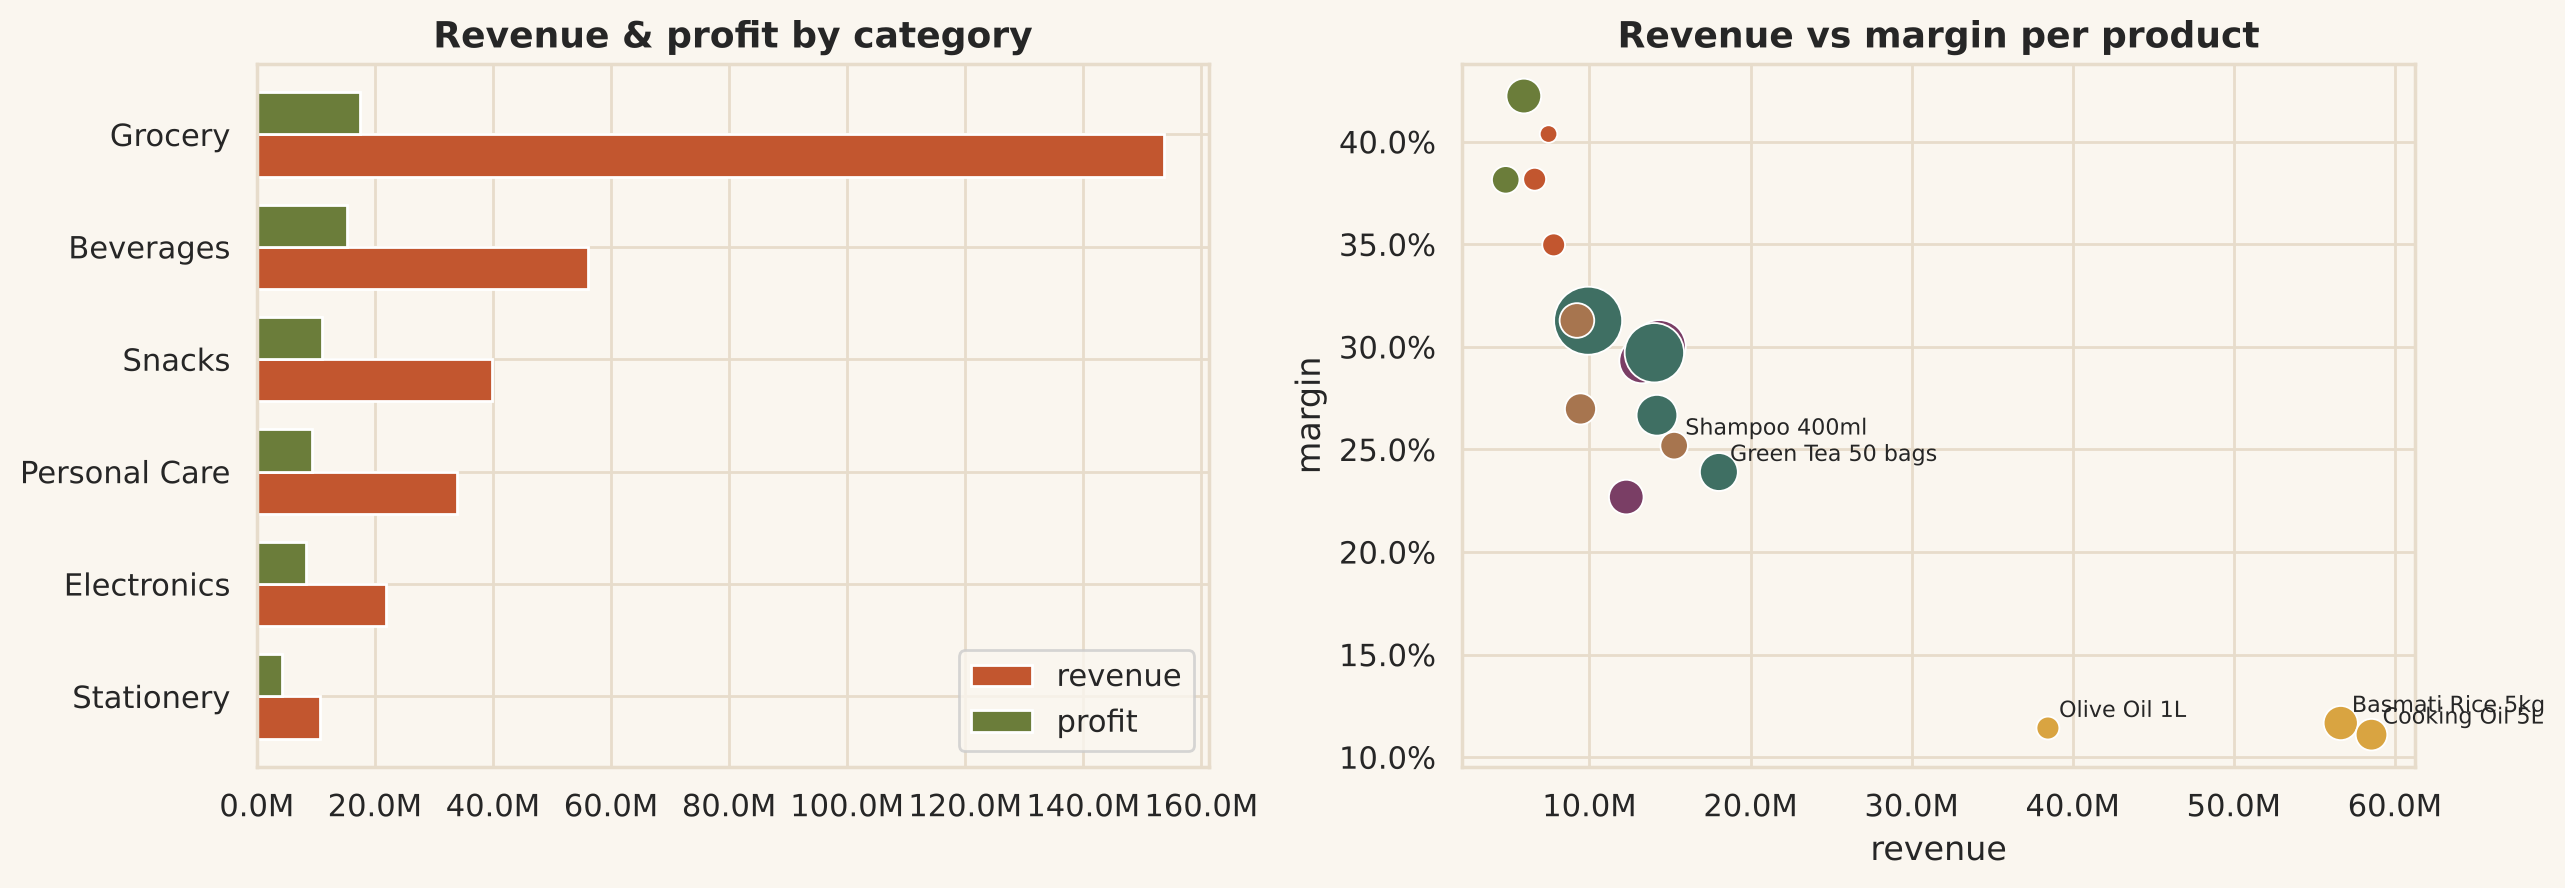

,product,category,units,revenue,profit,margin
4,Cooking Oil 5L,Grocery,20821,"58,546,940","6,494,440",11.1%
2,Basmati Rice 5kg,Grocery,23826,"56,638,365","6,603,765",11.7%
11,Olive Oil 1L,Grocery,12389,"38,460,800","4,391,050",11.4%
6,Green Tea 50 bags,Beverages,28594,"18,035,062","4,309,942",23.9%
14,Shampoo 400ml,Personal Care,16545,"15,258,282","3,842,232",25.2%
13,Potato Chips 150g,Snacks,52815,"14,338,324","4,303,474",30.0%
12,Orange Juice 1L,Beverages,32524,"14,191,785","3,784,105",26.7%
15,Soft Drink 1.5L,Beverages,65748,"14,031,072","4,168,872",29.7%


In [7]:
prod = df.groupby(['product', 'category']).agg(units=('quantity', 'sum'), revenue=('revenue', 'sum'), profit=('profit', 'sum')).reset_index()
prod['margin'] = prod['profit'] / prod['revenue']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
cat = prod.groupby('category')[['revenue', 'profit']].sum().sort_values('revenue')
cat.plot.barh(ax=axes[0], color=[PALETTE[0], PALETTE[1]], width=.75)
axes[0].xaxis.set_major_formatter(millions); axes[0].set_title('Revenue & profit by category'); axes[0].set_ylabel('')
sns.scatterplot(data=prod, x='revenue', y='margin', hue='category', size='units', sizes=(40, 600), ax=axes[1], legend=False)
for _, r in prod.nlargest(5, 'revenue').iterrows():
    axes[1].annotate(r['product'], (r['revenue'], r['margin']), fontsize=8, xytext=(4, 4), textcoords='offset points')
axes[1].xaxis.set_major_formatter(millions); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title('Revenue vs margin per product')
plt.tight_layout(); plt.show()
prod.sort_values('revenue', ascending=False).head(8).style.format({'revenue': '{:,.0f}', 'profit': '{:,.0f}', 'margin': '{:.1%}'})

**Insight:** Grocery is about half of revenue but earns only ~11% margin, while Stationery (~40%) and Electronics accessories (~38%) are the most profitable — good candidates for counter-side placement and bundles with grocery staples.

## 5. Customer segmentation — RFM + K-Means

In [8]:
rfm = rfm_segments(df)
summary = rfm.groupby('segment').agg(customers=('customer_id', 'count'), avg_recency_days=('recency', 'mean'), avg_visits=('frequency', 'mean'), revenue=('monetary', 'sum'))
summary['share_of_revenue'] = summary['revenue'] / summary['revenue'].sum()
summary.sort_values('revenue', ascending=False).style.format({'avg_recency_days': '{:.0f}', 'avg_visits': '{:.1f}', 'revenue': '{:,.0f}', 'share_of_revenue': '{:.1%}'})

,customers,avg_recency_days,avg_visits,revenue,share_of_revenue
segment,,,,,
Champions,179,4,245.0,"133,528,268",56.1%
Loyal,532,13,40.2,"65,301,772",27.4%
Occasional,709,42,15.3,"32,575,084",13.7%
At risk,379,137,6.1,"6,654,040",2.8%


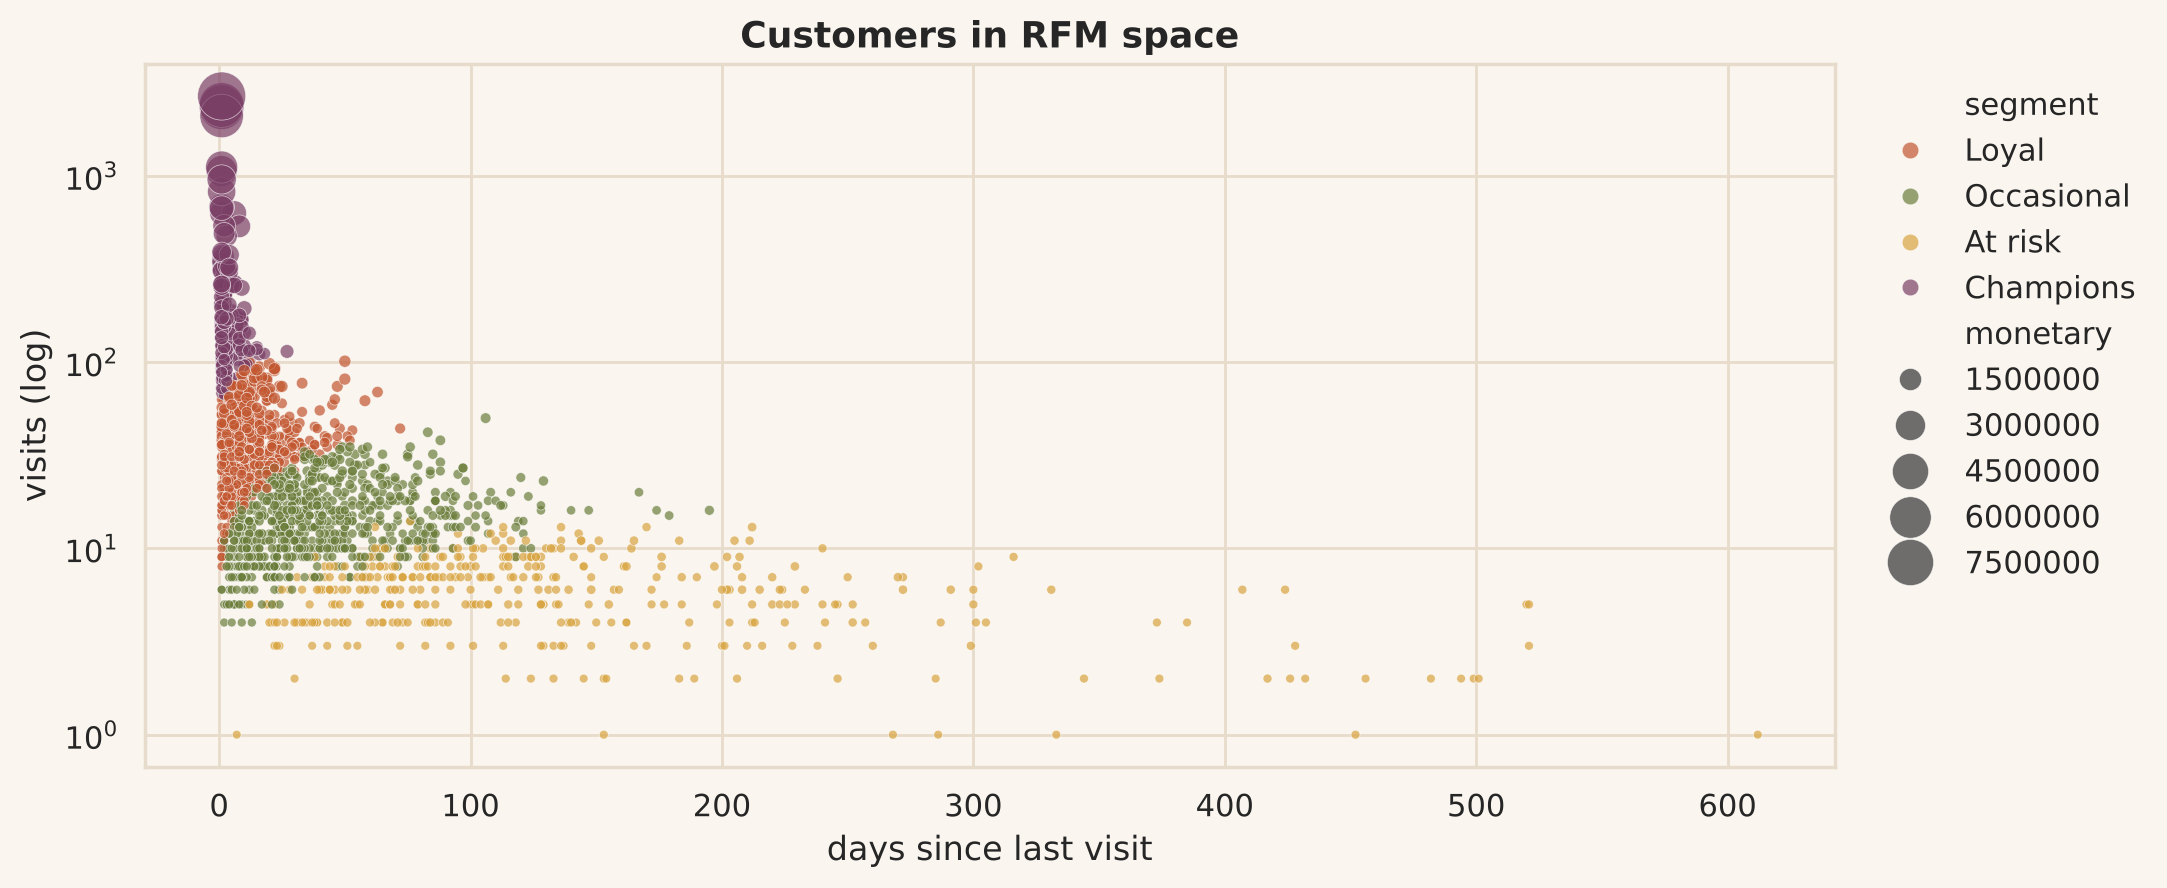

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.scatterplot(data=rfm, x='recency', y='frequency', hue='segment', size='monetary', sizes=(10, 300), alpha=.7, ax=ax)
ax.set_yscale('log'); ax.set_title('Customers in RFM space'); ax.set_xlabel('days since last visit'); ax.set_ylabel('visits (log)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
plt.tight_layout(); plt.show()

## 6. Forecast — next 6 months

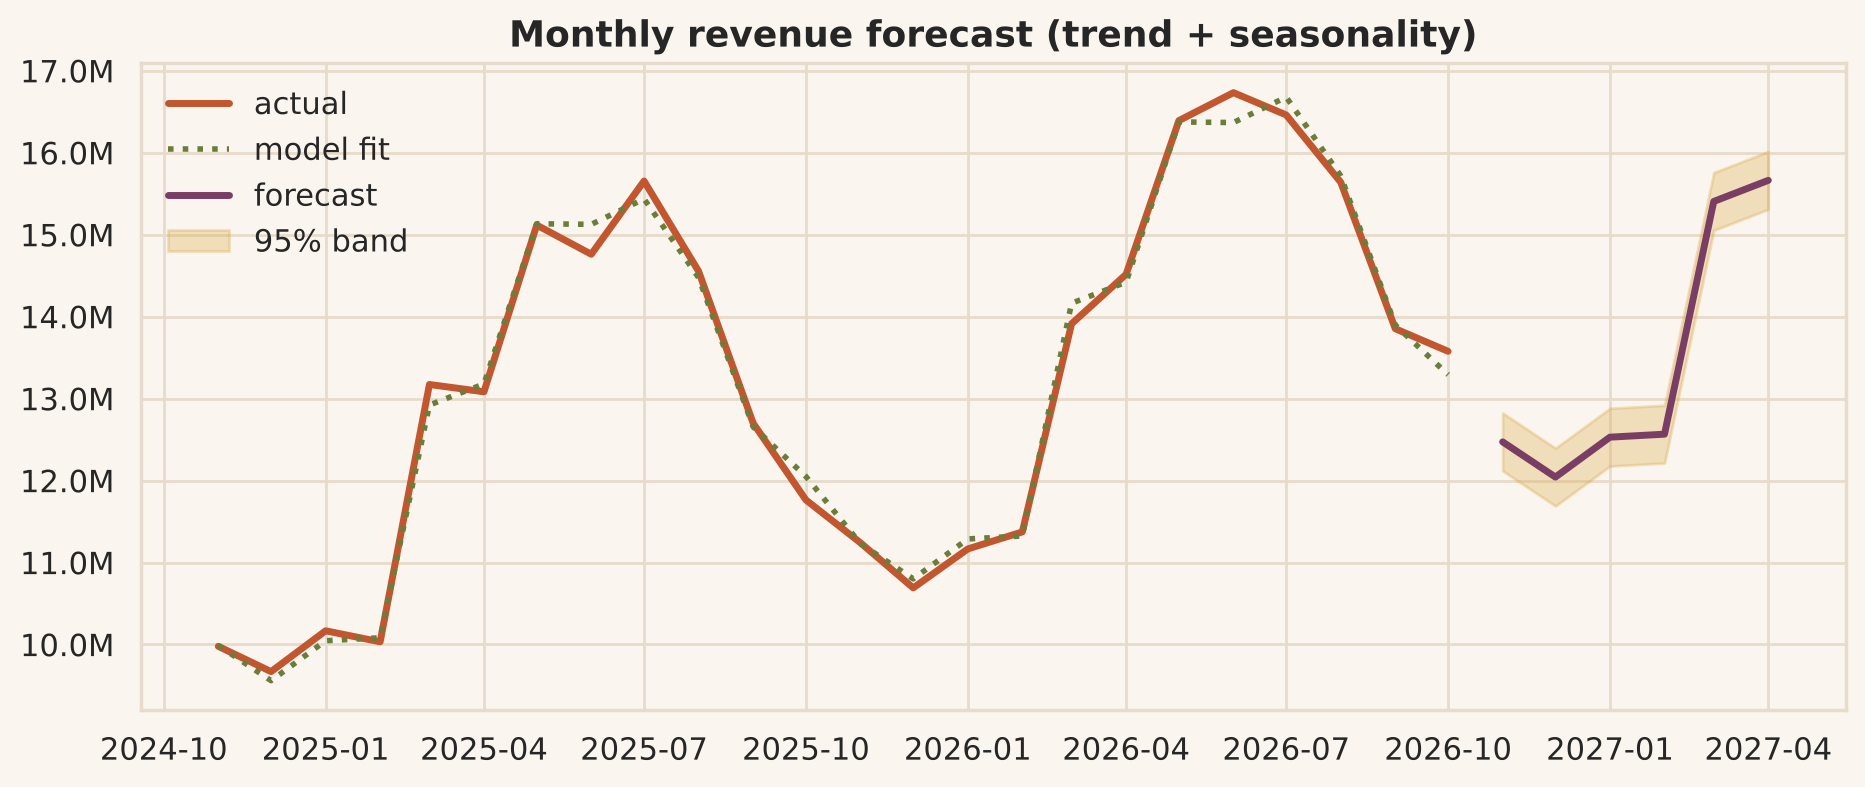

In-sample MAPE: 1.0%


,month,low,forecast,high
24,2026-11-01 00:00:00,"12,119,294","12,471,963","12,824,632"
25,2026-12-01 00:00:00,"11,689,931","12,042,600","12,395,269"
26,2027-01-01 00:00:00,"12,176,736","12,529,405","12,882,073"
27,2027-02-01 00:00:00,"12,213,240","12,565,909","12,918,578"
28,2027-03-01 00:00:00,"15,052,579","15,405,248","15,757,917"
29,2027-04-01 00:00:00,"15,309,965","15,662,634","16,015,303"


In [10]:
f = forecast_monthly(df, 6)
hist, fut = f[f['revenue'].notna()], f[f['forecast'].notna()]
fig, ax = plt.subplots()
ax.plot(hist['month'], hist['revenue'], color=PALETTE[0], lw=2.5, label='actual')
ax.plot(hist['month'], hist['fitted'], color=PALETTE[1], ls=':', lw=2, label='model fit')
ax.plot(fut['month'], fut['forecast'], color=PALETTE[3], lw=2.5, label='forecast')
ax.fill_between(fut['month'], fut['low'], fut['high'], color=PALETTE[2], alpha=.3, label='95% band')
ax.yaxis.set_major_formatter(millions); ax.set_title('Monthly revenue forecast (trend + seasonality)'); ax.legend(frameon=False)
plt.show()
mape = (abs(hist['revenue'] - hist['fitted']) / hist['revenue']).mean()
print(f'In-sample MAPE: {mape:.1%}')
fut[['month', 'low', 'forecast', 'high']].style.format({'low': '{:,.0f}', 'forecast': '{:,.0f}', 'high': '{:,.0f}'})

### Restock planner (14 days of cover)

In [11]:
restock_suggestions(df).head(10).style.format({'avg_daily_units': '{:.1f}'})

,product,avg_daily_units,units_for_cover
0,Mineral Water 1.5L,119.5,1673
1,Soft Drink 1.5L,87.7,1228
2,Potato Chips 150g,72.4,1014
3,Biscuits Family Pack,52.6,737
4,Orange Juice 1L,50.4,707
5,Green Tea 50 bags,41.6,583
6,Notebook A5,34.1,478
7,Basmati Rice 5kg,33.1,463
8,Toothpaste 120g,32.1,449
9,Dark Chocolate 100g,31.3,439


## 7. Recommendations

1. **Staff for the peak.** Add a second cashier on Friday/Saturday 5–8 pm in Clifton, the highest-traffic store.
2. **Protect the top sellers.** Use the restock planner to set reorder levels for the top 10 products — stock-outs there cost the most revenue.
3. **Grow margin, not just volume.** Promote high-margin Snacks and Stationery at the counter; bundle them with grocery staples.
4. **Win back at-risk customers.** A targeted voucher to the *At risk* segment is cheaper than acquiring new customers.
5. **Plan budgets with the forecast.** Use the forecast's lower band as the conservative case for purchasing.

*Limitations:* synthetic data; forecast is a transparent baseline — the next iteration would back-test on a holdout period and compare with SARIMA / Prophet.